In [68]:
# -*- coding: utf-8 -*-
from turtle import title
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import tempfile
import os
from ansys.aedt.core import generate_unique_name
from ansys.aedt.core import Desktop, Hfss, constants
from ansys.aedt.core.modeler.cad.object_3d import Object3d

In [69]:
tmpfold = tempfile.gettempdir()

temp_folder = os.path.join(
    tmpfold,
    generate_unique_name("Antenna")
)

if not os.path.exists(temp_folder):
    os.mkdir(temp_folder)

non_graphical = os.getenv(
    "PYAEDT_NON_GRAPHICAL",
    "False"
).lower() in ("true", "1", "t")

d = Desktop(
    "2025.1",
    non_graphical=non_graphical,
    new_desktop=True
)

PyAEDT INFO: Python version 3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:42:04) [MSC v.1943 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.17.1.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: Log on console is enabled.
PyAEDT INFO: Log on file C:\Users\LUIS~1.COS\AppData\Local\Temp\pyaedt_luis.costa_50b115fe-76e5-4a75-8b07-3bd48bcacc15.log is enabled.
PyAEDT INFO: Log on AEDT is enabled.
PyAEDT INFO: Debug logger is disabled. PyAEDT methods will not be logged.
PyAEDT INFO: Launching PyAEDT with gRPC plugin.
PyAEDT INFO: New AEDT session is starting on gRPC port 59688.
PyAEDT INFO: Electronics Desktop started on gRPC port: 59688 after 17.117431163787842 seconds.
PyAEDT INFO: AEDT installation Path C:\Program Files\ANSYS Inc\v251\AnsysEM
PyAEDT INFO: Ansoft.ElectronicsDesktop.2025.1 version started with process ID 2724.


In [70]:
P = 21
h = 0.1
hR = 49.3*2+h
t = 1.25373
w = 16.9254
m = 17.55224
distance = 49.3
phi_inc = 0
theta_inc = 0   

hfss = Hfss(solution_type="Modal")
hfss.modeler.model_units = "mm"

p = hfss.modeler.primitives


PyAEDT INFO: Python version 3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:42:04) [MSC v.1943 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.17.1.
PyAEDT INFO: Returning found Desktop session with PID 2724!
PyAEDT INFO: Project Project13 has been created.
PyAEDT INFO: No design is present. Inserting a new design.
PyAEDT INFO: Added design 'HFSS_9RI' of type HFSS.
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec


In [71]:
pet = hfss.materials.add_material("pet")
pet.permittivity = 3.5
pet.dielectric_loss_tangent = 0.008


substract = p.create_box(
    [-0.5 ,-0.5 ,0],
    [P, P, h],
    material="pet",
    name="substract"
)

airbox = p.create_box(
    [-0.5 ,-0.5 ,-hR/2],
    [P, P, hR],
    name="airbox"
)


top_side = p.create_rectangle(
    constants.PLANE.XY,
    (t+(m-w)/2 ,m+t ,h),
    (w, t),
    name="top_side"
) 

right_side = p.create_rectangle(
    constants.PLANE.XY,
    (t+m ,t + (m-w)/2 ,h) ,
    (t, w),
    name="right_side"
) 

mid_sideX = p.create_rectangle(
    constants.PLANE.XY,
    (t ,(2*t+(m-w)+w)/2-t/2 ,h) ,
    (m, t),
    name="mid_sideX"
) 

mid_sideX1 = p.create_rectangle(
    constants.PLANE.XY,
    ((2*t+(m-w)+w)/2-t/2 ,t ,h) ,
    (t, m),
    name="mid_sideX1"
) 

left_side = p.create_rectangle(
    constants.PLANE.XY,
    (-0 ,t + (m-w)/2 ,h) ,
    (t, w),
    name="left_side"
) 

bot_side = p.create_rectangle(
    constants.PLANE.XY,
    (t+(m-w)/2 ,0 ,h) ,
    (w, t),
    name="bot_side"
) 

p.unite([top_side, right_side])
p.unite([top_side, mid_sideX])
p.unite([top_side, mid_sideX1])
p.unite([top_side, left_side])
p.unite([top_side, bot_side])

hfss.assign_perfect_e(
    top_side.name
)
hfss.change_material_override()


PyAEDT INFO: Materials class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Adding new material to the Project Library: pet
PyAEDT INFO: Material has been added in Desktop.
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Union of 2 objects has been executed.
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Union of 2 objects has been executed.
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Uni

True

In [72]:
lattice = hfss.auto_assign_lattice_pairs(
    assignment=airbox.name,
)

z_normal_faces = []
max_value_z = -float("inf")
min_value_z = float("inf")
top_face = None
bottom_face = None

for face in airbox.faces:
    center = p.get_face_center(face.id)
    z = center[2]
    if z > max_value_z:
        max_value_z = z
        top_face = face.id
        z_normal_faces.append(top_face)
    if z < min_value_z:
        min_value_z = z
        bottom_face = face.id
        z_normal_faces.append(bottom_face)

In [73]:
obj = hfss.modeler.primitives["airbox"]
bbox= obj.bounding_box
min_x, min_y, min_z= bbox[:3]
max_x, max_y, max_z = bbox[3:]

# Passo 1: Cria porta com 1 modo
port1 = hfss.create_floquet_port(
    assignment=[top_face],
    name="port1",
    lattice_origin=[min_x, min_y, max_z],
    lattice_a_end=[max_x, min_y, max_z],
    lattice_b_end=[min_x, max_y, max_z],
    modes=2,
    deembed_distance=distance,
    renormalize=True
)

port2 = hfss.create_floquet_port(
    assignment=[bottom_face],
    name="port2",
    lattice_origin=[min_x, min_y, min_z],
    lattice_a_end=[max_x, min_y, min_z],
    lattice_b_end=[min_x, max_y, min_z],
    modes=2,
    deembed_distance=distance,
    renormalize=True
)

PyAEDT INFO: Boundary Floquet Port port1 has been created.
PyAEDT INFO: Boundary Floquet Port port2 has been created.


In [74]:
def configurar_modo_tm(floquet, modo_nome):
    modo = floquet.props["Modes"][modo_nome]
    modo["IsEnabled"] = False
    modo["AffectsRefinement"] = False
    floquet.update()
    print(f"✅ Modo TM aplicado em {modo_nome}")

configurar_modo_tm(port1, "Mode1")
configurar_modo_tm(port2, "Mode1")



✅ Modo TM aplicado em Mode1
✅ Modo TM aplicado em Mode1


In [75]:
my_plot = hfss.plot(show=False, plot_air_objects=False)
my_plot.show_axes = False
my_plot.show_grid = False
my_plot.isometric_view = True
my_plot.plot(
    os.path.join(hfss.working_directory, "FSS.jpg")    
)

setup = hfss.create_setup("MySetup")

PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec


Widget(value='<iframe src="http://localhost:58386/index.html?ui=P_0x1eddacbb910_4&reconnect=auto" class="pyvis…

In [76]:
def SingleFrequency(
    freq,
    maxPasses,
    maxDeltaS= 0.01,
    name="MySetup"
):
    #hfss.create_open_region(frequency=freq)
    setup.props["Frequency"] = freq
    setup.props["MaximumPasses"] = maxPasses
    setup.props["MaxDeltaS"] =maxDeltaS
    setup.props["UseIterativeSolver"] = True
    setup.props["SaveRadFieldsOnly"] = True
    setup.props["RadiationSetup"] = "3D"
    setup.props["ComputeFarFields"] = True

SingleFrequency("5GHz", 20,0.02)



In [77]:
def LinearCountSweep(
    fStart,
    fStop,
    freqPonts=401,
    units="GHz",
    saveFields=True,
    saveRadFields=True
):
    sweep = hfss.create_linear_count_sweep(
        setup=setup.name,
        units=units,
        start_frequency=fStart,
        stop_frequency=fStop,
        num_of_freq_points = freqPonts,
        name= "sweep",
        sweep_type="Interpolating",
        save_fields=saveFields,
        save_rad_fields=saveRadFields
    )
LinearCountSweep(2.5,5.0)


PyAEDT INFO: Linear count sweep sweep has been correctly created.


In [78]:
def SaveAnalyseSetup(
    nameFolder= "FSS.aedt",
    setup="MySetup"
):
    hfss.save_project(os.path.join(temp_folder, nameFolder))
    hfss.analyze_setup(setup)

SaveAnalyseSetup("FSS.aedt")

PyAEDT INFO: Project FSS Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup MySetup
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Design setup MySetup solved correctly in 0.0h 1.0m 23.0s


In [79]:

solutions = hfss.post.get_solution_data(
    expressions=hfss.get_traces_for_plot(category="dB(S")
)

solutions.enable_pandas_output = True

S_Real = solutions._init_solution_data_real()
index = 0
S_real1 = S_Real[list(S_Real.keys())[index]]
listaReal = []
listaReal2 = []
dataVazioGap = {}
dfRealGap = pd.DataFrame(dataVazioGap)
for i,c in S_real1.items():
    #a = i[0]
    #listaReal.append(a)
    listaReal.append(float(i[0]))
    #c=S_real1[i]
    listaReal2.append(float(c))
dfRealGap.insert(0, "Frequency [GHz]", listaReal, True)
dfRealGap.insert(1, "|$S_{21}$| [dB]", listaReal2, True)
indexValueMin = dfRealGap['|$S_{21}$| [dB]'].idxmin()

dfRealGap.to_csv('S11_Gap.csv')

PyAEDT WARNING: Solution Data failed to load. Check solution, context or expression.
PyAEDT WARNING: No Data Available. Check inputs


AttributeError: 'bool' object has no attribute 'enable_pandas_output'

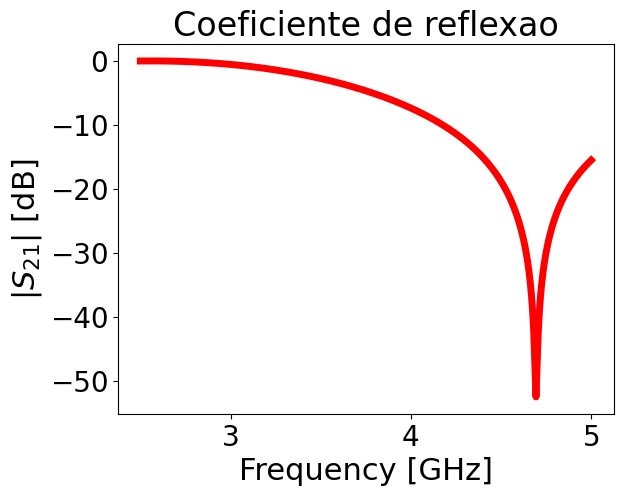

In [ ]:
def Grafico(
    df,
    title,
    nameX='Frequency [GHz]',
    nameY='Result',
    colorGraf='red'
):
    valorEixoY = df[nameY].to_numpy()
    valorEixoX = df[nameX].to_numpy()
    fig, ax = plt.subplots()
    ax.plot(valorEixoX, valorEixoY, color='red', linewidth = 5)
    ax.set_xlabel(nameX, fontsize = 22)
    ax.set_ylabel(nameY, fontsize = 22)
    plt.tick_params(axis='both', which='major', labelsize=20)
    plt.title(title, fontsize=24)
    plt.show()

Grafico(
    dfRealGap,
    "Coeficiente de reflexao",
    "Frequency [GHz]",
    "|$S_{21}$| [dB]",
)

In [80]:
d.release_desktop()

PyAEDT INFO: Desktop has been released and closed.


True